In [17]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import matplotlib.pyplot as plt

from spice.libs.spice_bootstrap import run_spice_bootstrap
from spice.libs.plotting.tree import plot_cn_tree, plot_cn_probabilities

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


This demo provides instructions to run SPICE on the required input data within a Jupyter notebook. The demo uses input data generated in the accompanying demo within the CNA simulation framework repository.

In [3]:
spice_input_data = pd.read_csv('./sim/sim_cn_seg_leaf_profiles.tsv.gz', sep='\t')
spice_input_data

,Node,Chr,Pos,Start,End,Allele,CN
0,5,1,1,100000,123100000,A,4
1,5,1,1,100000,123100000,B,2
2,5,1,2,123100000,138200000,A,2
3,5,1,2,123100000,138200000,B,0
4,5,1,3,138200000,138900000,A,4
...,...,...,...,...,...,...,...
1865,9,22,1,100000,300000,B,4
1866,9,22,2,300000,14600000,A,2
1867,9,22,2,300000,14600000,B,2
1868,9,22,3,14600000,50818468,A,2


### Input to the SPICE

SPICE takes in input multiple parameters:

`leaves_df`: A DataFrame containing the copy number profiles of each leaf (clone), with columns `Node`, `Chr`, `Start`, `End`, `Allele` (`A` or `B`; may be left out if `allele_specific=False`) and `CN`. Each row is one genomic segment or bin of one allele in one leaf, and every leaf must have the same segments or bins. Consecutive segments or bins with the same copy numbers in every leaf are merged, and the outputs are given for these merged segments. Other columns (including `Pos`) are ignored.

`min_seg_size`: The minimum segment size (in base pairs) considered in the ILP model of SPICE. Segments smaller than this threshold undergo phylogenetic reconstruction using the alternative focal evolutionary model (`default=5e4`).

`max_n_segs`: The maximum number of segments to include in the ILP model. Segments are ranked in decreasing order of size and the top `max_n_segs` are included. The other segments undergo phylogenetic reconstruction using the alternative focal evolutionary model. If None, `min_seg_size` is used instead (default=None).

`keep_consec_segs`: Only used when either of `min_seg_size` or `max_n_segs` are active. Moves small segments into the ILP so that every segment left to the focal evolutionary model has a neighbouring segment in the ILP. (`default=False`).

`allele_specific`: If True, inference is performed on allele-specific copy number profiles (major/minor). If False, total copy number is used (`default=True`).

`phase_alleles`: Determines whether alleles should be phased before inference (`default=False`).

`leaf_dependent_phasing`: If False, phasing is performed independently for each leaf. If True, global phasing is used across all leaves (`default=True`).

`max_cn`: The maximum copy number per segment. Copy numbers above this threshold are truncated (`default=8`).

`focal_max_cn`: The maximum copy number in the focal evolutionary model. If None, `max_cn` is used (`default=None`).

`verbose`: Controls the verbosity of console output. If True, detailed progress and debug messages are printed (`default=False`).

`rs`: Random seed (`default=1`).

`n_threads`: The number of computational threads used for parallel execution (`default=1`).

`time_limit`: The maximum time (in hours) allowed for the inference process to complete (`default=5`).

`weight_wgd`: Whether to assign additional weight (where the weight is equivalent to the `max_cn` value) to whole genome duplication (WGD) events in the ILP (`default=True`).

`wgd_fract_genome`: The fraction of each allele (or of the genome, in total copy number mode) that must be affected by a WGD event in a child node to keep the inference of WGD from the ILP model (`default=0.5`).

`multiple_solutions`: If True, multiple possible phylogenetic solutions are enumerated by SPICE, otherwise only the optimal tree is returned. (`default=True`)

`solution_pool_size`: The number of alternative ancestral node solutions to enumerate from the ILP model, shared between the topologies in proportion to their bootstrap frequency (`default=1000`).

`max_cutoff`: Only solutions with a cost of at most this multiple of the optimal cost are enumerated (`default=2`).

`n_bootstraps`: The number of bootstrap replicates performed inferring phylogenetic tree topologies (`default=1000`).

`fixed_topology`: If tuple of (parent, child) relationships describing the topology is provided, the tree topology is fixed, and only ancestral nodes are inferred (`default=False`)

`topology_prop_limit`: The minimum fraction of bootstrap replicates that must give a topology for it to be used, in addition to the `topology_topn` most frequent topologies (`default=0.025`).

`topology_topn`: The number of most frequent bootstrapped topologies that are always used (`default=10`).

`initnodes`: Copy number profiles of the internal nodes (e.g. from MEDICC2) to warm-start the ILP, with the same columns and segments as `leaves_df`. Requires `fixed_topology` (`default=None`).

`debug`: Outputs more detailed information for debugging only: all variables of the ILP model (`total_debug`), the topologies used (`topologies`) and the mapping between the input bins and SPICE's internal segments (`mapping`) (`default=False`).

`rm_small_segs`: If True, small segments (set by `min_seg_size` or `max_n_segs`) are removed instead of being reconstructed with the focal evolutionary model (`default=False`).

`rank_multiple_trees`: If True, multiple inferred trees are ranked according to their probability (`default=True`).

`output_type`: Specifies the output mode. Options include 'return' (returns results to the session), 'save' (writes results to disk) or 'both' (`default='save'`).

`output_dir`: Directory to which the outputs, the log and the Gurobi node files are saved; created if it doesn't exist. If None, the current directory is used (`default=None`).

In [5]:
spice_res = run_spice_bootstrap(spice_input_data,
                        min_seg_size=5e5, # For this demo, 5e5 is used as opposed to default 5e4 to demosntrate the use of the different evolutionary models 
                        max_n_segs=None,
                        keep_consec_segs=False,
                        allele_specific=True,
                        phase_alleles=False,
                        leaf_dependent_phasing=True,
                        max_cn=8,
                        focal_max_cn=None,
                        verbose=False,
                        rs=1,
                        n_threads=1,
                        time_limit=5,
                        weight_wgd=True,
                        wgd_fract_genome=0.5,
                        multiple_solutions=True,
                        solution_pool_size=250, # This is a reduced solution pool size compared to the default value (1000) for the purposes of the demo
                        max_cutoff=2,
                        n_bootstraps=1000,
                        fixed_topology=False,
                        topology_prop_limit=0.025,
                        topology_topn=10,
                        initnodes=None,
                        debug=False,
                        rm_small_segs=False,
                        rank_multiple_trees=True,
                        output_type='both',
                        output_dir='./spice_output')

SPICE 2026-11-18 15:59:03,823 | STEP | spice_bootstrap.py >>> Processing input data
SPICE 2026-11-18 15:59:03,829 | WARNING | input.py >>> Ignoring columns of leaves_df that SPICE does not use: ['Pos']
SPICE 2026-11-18 15:59:04,073 | INFO | input.py >>> Total number of segments before filtering: 374
SPICE 2026-11-18 15:59:04,090 | INFO | input.py >>> Total number of segments after filtering: 262
SPICE 2026-11-18 15:59:04,589 | INFO | input.py >>> Processed input CN profiles. 5 leaves with 174 final segments
SPICE 2026-11-18 15:59:04,592 | INFO | spice_bootstrap.py >>> Input data valid
SPICE 2026-11-18 15:59:04,593 | STEP | spice_bootstrap.py >>> Bootstrapping topologies
Progress: |██████████████████████████████| 100.0% Complete [[2026-Nov-18 15:59:55]Pair: 914423][2K
SPICE 2026-11-18 15:59:56,060 | INFO | spice_bootstrap.py >>> Bootstrapping complete : 4 unique topologies
SPICE 2026-11-18 15:59:56,061 | STEP | spice_bootstrap.py >>> Running SPICE ILP: total time limit = 18000s
SPICE 20

The following files are output from SPICE:

- `total_nodes_multisol`: The output copy number profiles by SPICE for every solution enumerated in the enumerate ILP.

In [6]:
spice_res['total_nodes_multisol']

,tree_id,Solution,Node,Chr,Start,End,cnA,cnB,DeletionsA,DeletionsB,GainsA,GainsB,cn_model
0,1,m1,0,1,100000,123100000,1,1,0,0,0,0,ilp_model
1,1,m1,0,1,123100000,138200000,1,1,0,0,0,0,ilp_model
2,1,m1,0,1,138200000,138900000,1,1,0,0,0,0,ilp_model
3,1,m1,0,1,138900000,141800000,1,1,0,0,0,0,ilp_model
4,1,m1,0,1,141800000,143700000,1,1,0,0,0,0,ilp_model
...,...,...,...,...,...,...,...,...,...,...,...,...,...
469365,4,m251,clone_9,21,36400000,37700000,2,0,0,0,0,0,ilp_model
469366,4,m251,clone_9,21,37700000,46709983,2,0,0,0,0,0,ilp_model
469367,4,m251,clone_9,22,100000,300000,4,4,0,0,2,0,focal_model
469368,4,m251,clone_9,22,300000,14600000,2,2,0,0,0,0,ilp_model


- `total_edges_multisol`: The output edges of the phylogeny by SPICE for every solution enumerated in the enumerate ILP.

In [7]:
spice_res['total_edges_multisol']

,tree_id,Solution,Parent,Child,Events,Deletions,Gains,WGD,Total_cost,Gurobi_cost,Total_cost_focal,Total_cost_focal_interval,is_trunk
0,1,m1,0,1,26,15,11,1,109,117.0,329,195,True
1,1,m1,1,2,14,10,4,0,109,117.0,329,195,False
2,1,m1,1,3,3,3,0,0,109,117.0,329,195,False
3,1,m1,2,clone_5,14,5,9,0,109,117.0,329,195,False
4,1,m1,2,clone_6,12,6,6,0,109,117.0,329,195,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2254,4,m251,2,clone_7,13,5,8,0,126,134.0,364,218,False
2255,4,m251,3,4,12,9,3,0,126,134.0,364,218,False
2256,4,m251,3,clone_5,26,13,13,0,126,134.0,364,218,False
2257,4,m251,4,clone_8,12,5,7,0,126,134.0,364,218,False


- `total_nodes_optimal`: The output copy number profiles by SPICE for only the optimal solutions (one for each inferred topology) output by the optimal ILP.

In [8]:
spice_res['total_nodes_optimal']

,tree_id,Solution,Node,Chr,Start,End,cnA,cnB,DeletionsA,DeletionsB,GainsA,GainsB,cn_model
0,1,o1,0,1,100000,123100000,1,1,0,0,0,0,ilp_model
1,1,o1,0,1,123100000,138200000,1,1,0,0,0,0,ilp_model
2,1,o1,0,1,138200000,138900000,1,1,0,0,0,0,ilp_model
3,1,o1,0,1,138900000,141800000,1,1,0,0,0,0,ilp_model
4,1,o1,0,1,141800000,143700000,1,1,0,0,0,0,ilp_model
...,...,...,...,...,...,...,...,...,...,...,...,...,...
7475,4,o4,clone_9,21,36400000,37700000,2,0,0,0,0,0,ilp_model
7476,4,o4,clone_9,21,37700000,46709983,2,0,0,0,0,0,ilp_model
7477,4,o4,clone_9,22,100000,300000,4,4,0,0,2,0,focal_model
7478,4,o4,clone_9,22,300000,14600000,2,2,0,0,0,0,ilp_model


- `total_edges_optimal`: The output edges of the phylogeny by SPICE for only the optimal solutions (one for each inferred topology) output by the optimal ILP.

In [9]:
spice_res['total_edges_optimal']

,tree_id,Solution,Parent,Child,Events,Deletions,Gains,WGD,Total_cost,Gurobi_cost,Total_cost_focal,Total_cost_focal_interval,is_trunk
0,1,o1,0,1,26,15,11,1,109,117.996214,329,195,True
1,1,o1,1,2,14,10,4,0,109,117.996214,329,195,False
2,1,o1,1,3,3,3,0,0,109,117.996214,329,195,False
3,1,o1,2,clone_5,14,5,9,0,109,117.996214,329,195,False
4,1,o1,2,clone_6,12,6,6,0,109,117.996214,329,195,False
5,1,o1,3,4,8,5,3,0,109,117.996214,329,195,False
6,1,o1,3,clone_7,10,3,7,0,109,117.996214,329,195,False
7,1,o1,4,clone_8,11,5,6,0,109,117.996214,329,195,False
8,1,o1,4,clone_9,11,4,7,0,109,117.996214,329,195,False
9,2,o2,0,1,27,16,11,1,116,124.995992,343,208,True


- `total_events`: All events in each of the enumerated solutions output by SPICE. If small segments were filled, this also includes the events from the alternative focal evolutionary model.

In [10]:
spice_res['total_events']

,tree_id,Solution,Node,Chr,Start,End,Allele,Event,nEvents,cn_model,event_id
0,1,m1,1,1,100000,123100000,A,Gain,1,ilp_model,ilp_1.1.A.Gain.100000_123100000
1,1,m1,1,1,138200000,138900000,A,Gain,1,ilp_model,ilp_1.1.A.Gain.138200000_138900000
2,1,m1,1,1,141800000,143700000,A,Gain,1,ilp_model,ilp_1.1.A.Gain.141800000_143700000
3,1,m1,1,1,123100000,248956422,B,Deletion,1,ilp_model,ilp_1.1.B.Deletion.123100000_248956422
4,1,m1,1,2,100000,242193529,A,Gain,1,ilp_model,ilp_1.2.A.Gain.100000_242193529
...,...,...,...,...,...,...,...,...,...,...,...
70422,4,m251,clone_9,20,37600000,37900000,A,Gain,1,focal_model,focal_clone_9.20.A.Gain.37600000_37900000
70423,4,m251,clone_9,20,37900000,38200000,A,Gain,3,focal_model,focal_clone_9.20.A.Gain.37900000_38200000
70424,4,m251,clone_9,20,38200000,64444167,A,Gain,1,ilp_model,ilp_clone_9.20.A.Gain.27900000_64444167
70425,4,m251,clone_9,20,27900000,37600000,B,Deletion,1,ilp_model,ilp_clone_9.20.B.Deletion.27900000_37600000


- `solution_probabilities`: The calculated probabilities of each topology, CN profile, and overall solution probability for every solution enumerated by SPICE, along with the ranking of each solution and of its topology.

In [11]:
spice_res['solution_probabilities']

,tree_id,Solution,solution_rank,topology_rank,solution_log_prob,topology_log_prob,cn_log_prob,geometric_weight,Total_cost,Gurobi_cost,bootstrap_frequency,Tree
0,1,m3,1,1,-2.952005,-0.000002,-2.952003,8.000000e-01,109,117.0,0.974,"((0, 1), (1, 2), (1, 3), (2, clone_5), (2, clo..."
1,1,m5,1,1,-2.952005,-0.000002,-2.952003,1.600000e-01,110,118.0,0.974,"((0, 1), (1, 2), (1, 3), (2, clone_5), (2, clo..."
2,1,m10,1,1,-2.952005,-0.000002,-2.952003,1.600000e-01,110,118.0,0.974,"((0, 1), (1, 2), (1, 3), (2, clone_5), (2, clo..."
3,1,m12,1,1,-2.952005,-0.000002,-2.952003,1.600000e-01,110,118.0,0.974,"((0, 1), (1, 2), (1, 3), (2, clone_5), (2, clo..."
4,1,m13,1,1,-2.952005,-0.000002,-2.952003,1.600000e-01,110,118.0,0.974,"((0, 1), (1, 2), (1, 3), (2, clone_5), (2, clo..."
...,...,...,...,...,...,...,...,...,...,...,...,...
246,2,m249,165,2,-288.349969,-27.215745,-261.134224,1.024000e-05,116,124.0,0.020,"((0, 1), (1, 2), (1, 3), (2, clone_5), (2, clo..."
247,2,m245,166,2,-298.699792,-27.215745,-271.484047,1.024000e-05,116,124.0,0.020,"((0, 1), (1, 2), (1, 3), (2, clone_5), (2, clo..."
248,2,m247,166,2,-298.699792,-27.215745,-271.484047,1.024000e-05,116,124.0,0.020,"((0, 1), (1, 2), (1, 3), (2, clone_5), (2, clo..."
249,3,m250,167,3,-920.136179,-52.966751,-867.169427,1.310720e-10,123,131.0,0.005,"((0, 1), (1, 2), (1, clone_5), (2, 3), (2, clo..."


- `cn_probabilities`: The probability of each inferred ancestral copy number state, calculated for each phylogenetic topology (`tree_id`). `top_ranked_topology` is True for the most probable topology, and `top_ranked_solution` for the topology of the top-ranked solution.

In [12]:
spice_res['cn_probabilities']

,tree_id,top_ranked_topology,top_ranked_solution,Node,Chr,Start,End,Allele,CN,CN_probability
0,1,True,True,1,1,100000,123100000,A,4,1.0
1,1,True,True,1,1,100000,123100000,B,2,1.0
2,1,True,True,1,1,123100000,138200000,A,2,1.0
3,1,True,True,1,1,123100000,138200000,B,0,1.0
4,1,True,True,1,1,138200000,138900000,A,4,1.0
...,...,...,...,...,...,...,...,...,...,...
6260,4,False,False,4,22,100000,300000,B,4,1.0
6261,4,False,False,4,22,300000,14600000,A,2,1.0
6262,4,False,False,4,22,300000,14600000,B,2,1.0
6263,4,False,False,4,22,14600000,50818468,A,2,1.0


- `solve_info`: Information on the ILP solves of each topology (solve time, status, optimality gap and cost of both the optimal and the enumeration ILP, and the number of solutions found), plus the total run time and random seed.

In [13]:
spice_res['solve_info']

,parameter,value,tree_id
0,optimal_tree_solve_time,19.83081,1.0
1,optimal_tree_model_status,optimal,1.0
2,optimal_tree_gap,0.0,1.0
3,optimal_tree_total_cost,117.996214,1.0
4,optimal_tree_solve_time,21.269651,2.0
5,optimal_tree_model_status,optimal,2.0
6,optimal_tree_gap,0.0,2.0
7,optimal_tree_total_cost,124.995992,2.0
8,optimal_tree_solve_time,14.255896,3.0
9,optimal_tree_model_status,optimal,3.0


The output of SPICE can also be visualised using the plotting functions of SPICE. Specifically, it is possible to visualise the copy number profiles of individual solutions (here the top-ranked solution), or CN probabilities for any topology (here that of the top-ranked solution).

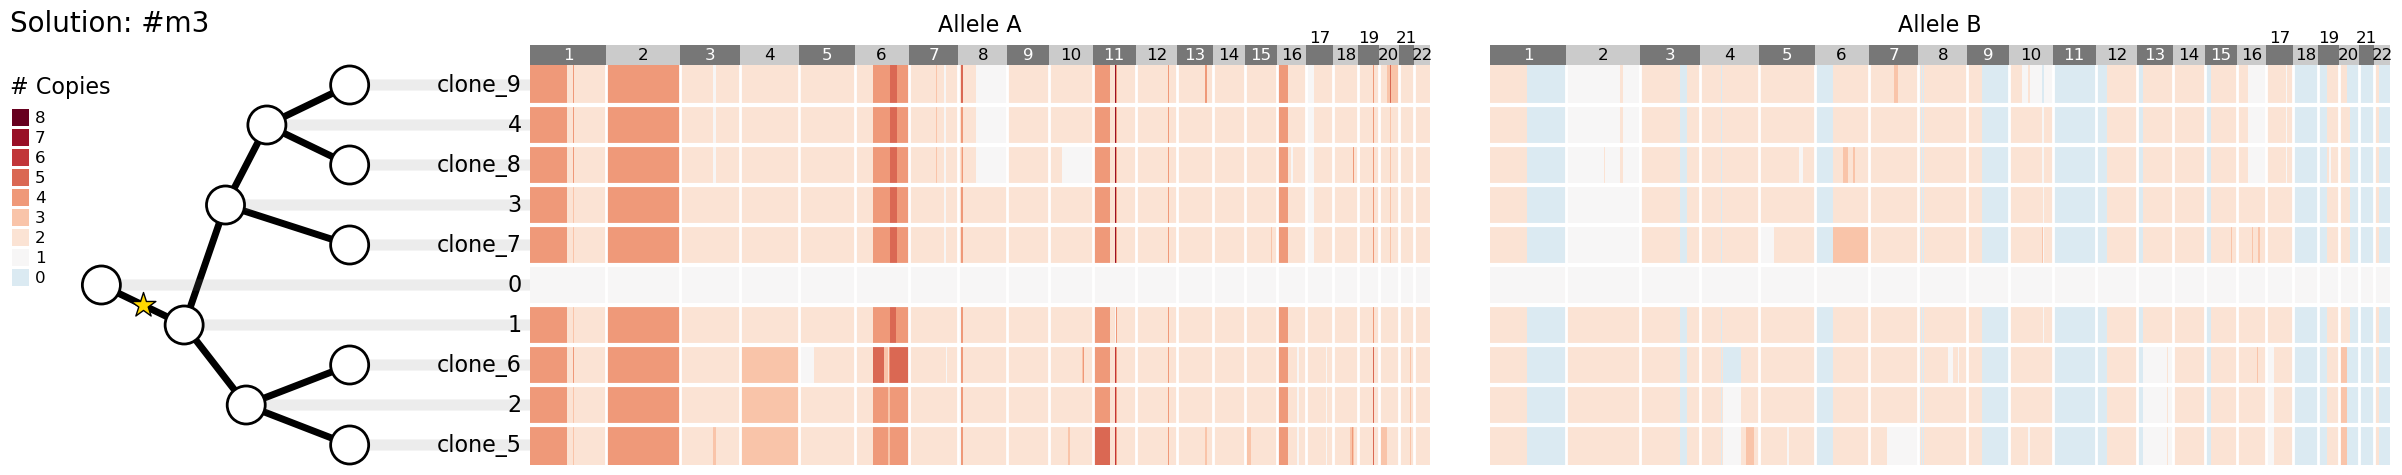

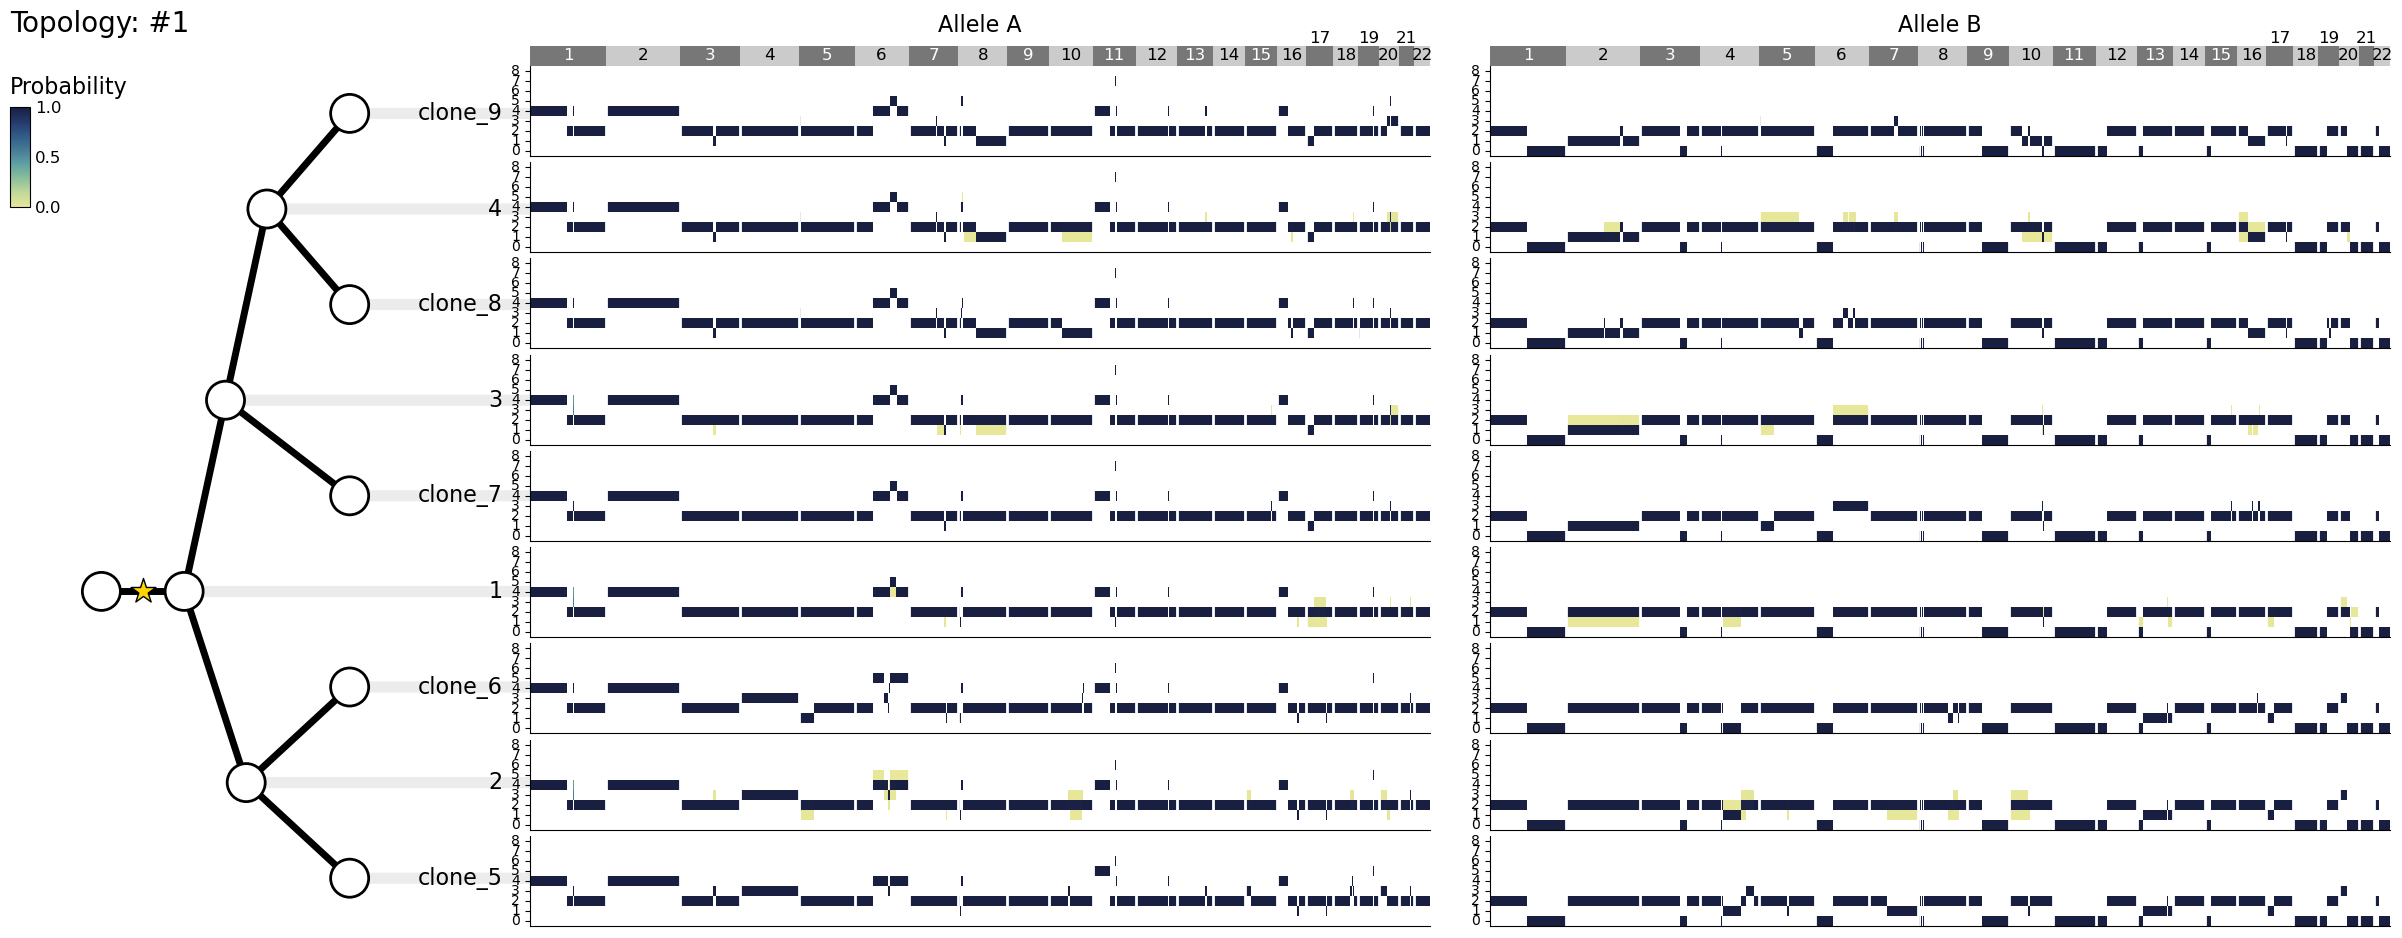

In [19]:
sp = spice_res['solution_probabilities']
top_solution = sp[sp['solution_rank'] == 1]

plot_cn_tree(spice_res['total_edges_multisol'], spice_res['total_nodes_multisol'], 
             leaf_order=None, cn_palette='RdBu_r', color_mapping={}, plot_root=True, solution=top_solution['Solution'].values[0], chrs='all', real_chr_lengths=True)
plt.gcf().savefig('./spice_output/cn_tree_plot.png', dpi=150, bbox_inches='tight')

plot_cn_probabilities(spice_res['total_edges_multisol'], spice_res['total_nodes_multisol'],
                      spice_res['cn_probabilities'], topology=top_solution['tree_id'].values[0], leaf_order=None, color_mapping={},
                      chrs='all', real_chr_lengths=True, plot_node_names=True)
plt.gcf().savefig('./spice_output/cn_probabilities_plot.png', dpi=150, bbox_inches='tight')